# 01 · Data Exploration and Protocol Verification

**Project.** Beyond Accuracy: Explanation Reliability Under Input Perturbations  
**Task.** Binary cat-vs-dog classification on Oxford-IIIT Pet with an ImageNet-pretrained ResNet18.  
**Role of this notebook.** Establish the data contract used by every downstream notebook: official splits, deterministic validation derivation, class balance, preprocessing, and perturbation families.

## Objectives

1. Download and materialize the official `trainval` and `test` splits.
2. Derive a validation partition **only** from `trainval`; never tune on `test`.
3. Quantify split sizes, class balance, and raw image geometry.
4. Verify label ranges and split disjointness.
5. Visualize preprocessing, augmentation, and the perturbation families used in Notebooks 03–05.

## Artifacts produced

- `experiments/results/dataset_split_summary.csv`
- `experiments/results/dataset_class_balance.csv`
- `experiments/results/dataset_image_geometry.csv`
- `figures/dataset_aspect_ratio.png`
- `figures/dataset_samples.png`
- `figures/perturbation_preview.png`

> **Scientific safeguard.** No test image is used for model selection. The test split is touched only for final evaluation and explanation analyses.

## Experimental protocol

| Stage | Split | Use |
|---|---|---|
| Training | `trainval` minus validation | Parameter optimization |
| Validation | 15% of `trainval` (seeded) | Loss monitoring and checkpoint selection |
| Test | official `test` | Final metrics and explanation stability |

- **Label space:** `binary-category` → `0 = cat`, `1 = dog` (two logits).
- **Input normalization:** ImageNet statistics, `mean = (0.485, 0.456, 0.406)`, `std = (0.229, 0.224, 0.225)`.
- **Resolution:** every image is resized to `224 × 224`.
- **Determinism:** Python, NumPy, and PyTorch seeds are fixed; the validation split uses a seeded generator.

The protocol is deliberately conservative: the validation set is a random subset of `trainval`, so the official test split remains an untouched held-out set.

## Environment and reproducibility

The cell below resolves the repository root, makes `src` importable, fixes all random seeds, and records the runtime. Paths are resolved relative to the repository root so the notebook behaves identically from JupyterLab, VS Code, or Colab.

In [1]:
import os
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image

from src.config import ExperimentConfig
from src.utils import seed_everything

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 180)
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "axes.titlesize": 11, "axes.labelsize": 10})

config = ExperimentConfig()
config.create_directories()
seed_everything(config.seed)

print(f"Project root : {PROJECT_ROOT}")
print(f"Python       : {sys.version.split()[0]}")
print(f"PyTorch      : {torch.__version__}")
print(f"CUDA         : {torch.cuda.is_available()}")
print(f"Seed         : {config.seed}")

Project root : C:\Users\hp\Desktop\Nouveau dossier (3)
Python       : 3.10.6
PyTorch      : 2.14.0+cpu
CUDA         : False
Seed         : 42


## Load the official splits

`load_oxford_pets` downloads the dataset if necessary, derives a seeded validation subset from `trainval`, and returns three `DataLoader` objects. Training augmentation is isolated from validation preprocessing by rebuilding the underlying dataset objects.

In [2]:
from src.data.oxford_pets import IMAGENET_MEAN, IMAGENET_STD, load_oxford_pets

train_loader, validation_loader, test_loader = load_oxford_pets(
    config.data_root,
    config.image_size,
    config.batch_size,
    config.num_workers,
    seed=config.seed,
)

train_dataset = train_loader.dataset
validation_dataset = validation_loader.dataset
test_dataset = test_loader.dataset
print(f"train={len(train_dataset)} | validation={len(validation_dataset)} | test={len(test_dataset)}")

train=3128 | validation=552 | test=3669


## Split composition

The table records the absolute and relative size of each partition. The shares are diagnostic only; the validation fraction is fixed by configuration, not by the data.

In [3]:
split_rows = []
for name, dataset in {
    "train": train_dataset,
    "validation": validation_dataset,
    "test": test_dataset,
}.items():
    split_rows.append({"split": name, "samples": len(dataset)})

split_table = pd.DataFrame(split_rows)
split_table["share_of_labeled_pool"] = split_table["samples"] / split_table["samples"].sum()
split_table.to_csv(config.output_root / "dataset_split_summary.csv", index=False)
split_table

,split,samples,share_of_labeled_pool
0,train,3128,0.425636
1,validation,552,0.075112
2,test,3669,0.499252


## Class balance

Class imbalance affects the interpretation of accuracy and of explanation maps. The table therefore reports per-class counts and shares, and the ratio of dogs to cats for each split.

In [4]:
def binary_labels(dataset):
    if isinstance(dataset, torch.utils.data.Subset):
        base, indices = dataset.dataset, dataset.indices
    else:
        base, indices = dataset, range(len(dataset))
    return np.asarray([base._bin_labels[index] for index in indices], dtype=int)

class_rows = []
for name, dataset in {
    "train": train_dataset,
    "validation": validation_dataset,
    "test": test_dataset,
}.items():
    labels = binary_labels(dataset)
    counts = np.bincount(labels, minlength=2)
    for class_index, class_name in enumerate(["cat", "dog"]):
        class_rows.append({
            "split": name,
            "class": class_name,
            "samples": int(counts[class_index]),
            "share": float(counts[class_index] / counts.sum()),
        })

class_table = pd.DataFrame(class_rows)
class_table.to_csv(config.output_root / "dataset_class_balance.csv", index=False)
class_table

,split,class,samples,share
0,train,cat,1016,0.324808
1,train,dog,2112,0.675192
2,validation,cat,172,0.311594
3,validation,dog,380,0.688406
4,test,cat,1183,0.322431
5,test,dog,2486,0.677569


In [5]:
balance_summary = class_table.pivot(index="split", columns="class", values="samples")
balance_summary["dog_to_cat_ratio"] = balance_summary["dog"] / balance_summary["cat"]
balance_summary

class,cat,dog,dog_to_cat_ratio
split,,,
test,1183,2486,2.101437
train,1016,2112,2.078740
validation,172,380,2.209302


## Raw image geometry

Oxford-IIIT Pet images have variable raw resolution and aspect ratio. Because the preprocessing resizes to a square, extreme aspect ratios may distort objects. Sampling raw file dimensions quantifies this risk without decoding the full dataset.

In [6]:
rng = np.random.default_rng(config.seed)
base_train = train_dataset.dataset if isinstance(train_dataset, torch.utils.data.Subset) else train_dataset
sample_indices = rng.choice(len(base_train), size=min(200, len(base_train)), replace=False)

geometry = []
for index in sample_indices:
    with Image.open(base_train._images[index]) as image:
        width, height = image.size
    geometry.append({"width": width, "height": height, "aspect_ratio": width / height})

geometry_table = pd.DataFrame(geometry)
geometry_summary = geometry_table.describe(percentiles=[0.05, 0.5, 0.95]).transpose()
geometry_summary.to_csv(config.output_root / "dataset_image_geometry.csv")
geometry_summary

,count,mean,std,min,5%,50%,95%,max
width,200.0,448.740000,224.934167,199.000,287.550,500.000000,500.0000,3264.000000
height,200.0,400.180000,173.824863,182.000,225.000,375.000000,500.0000,2448.000000
aspect_ratio,200.0,1.166961,0.321764,0.654,0.666,1.333333,1.5061,1.779359


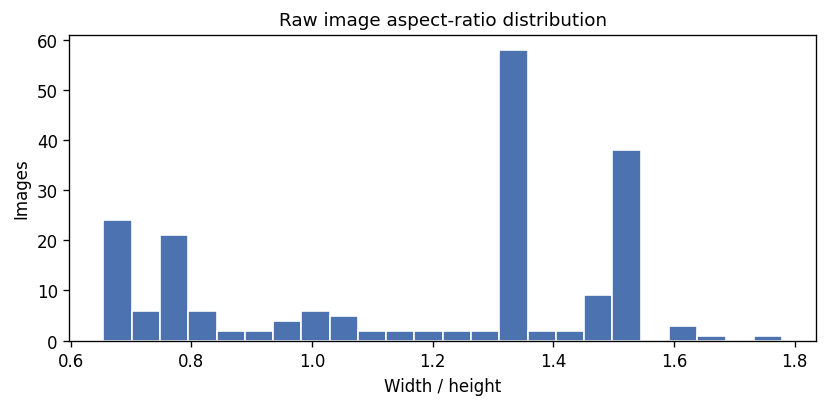

In [7]:
figure, axis = plt.subplots(figsize=(7, 3.5))
axis.hist(geometry_table["aspect_ratio"], bins=24, color="#4C72B0", edgecolor="white")
axis.set(title="Raw image aspect-ratio distribution", xlabel="Width / height", ylabel="Images")
figure.tight_layout()
figure.savefig(Path("figures") / "dataset_aspect_ratio.png", dpi=300)
plt.show()

## Preprocessing pipelines

Training and evaluation use different transform compositions. Augmentation is applied only during training; validation and test use deterministic resize, tensor conversion, and ImageNet normalization.

In [8]:
from src.data.oxford_pets import build_transforms

print("Training pipeline:")
print(build_transforms(config.image_size, train=True))
print()
print("Evaluation pipeline:")
print(build_transforms(config.image_size, train=False))

Training pipeline:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=0)
    ToTensor()
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
)

Evaluation pipeline:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
)


## Visual inspection of the training distribution

A small batch is denormalized for display. The labels shown are the binary targets used by the classifier, not the 37 breed labels.

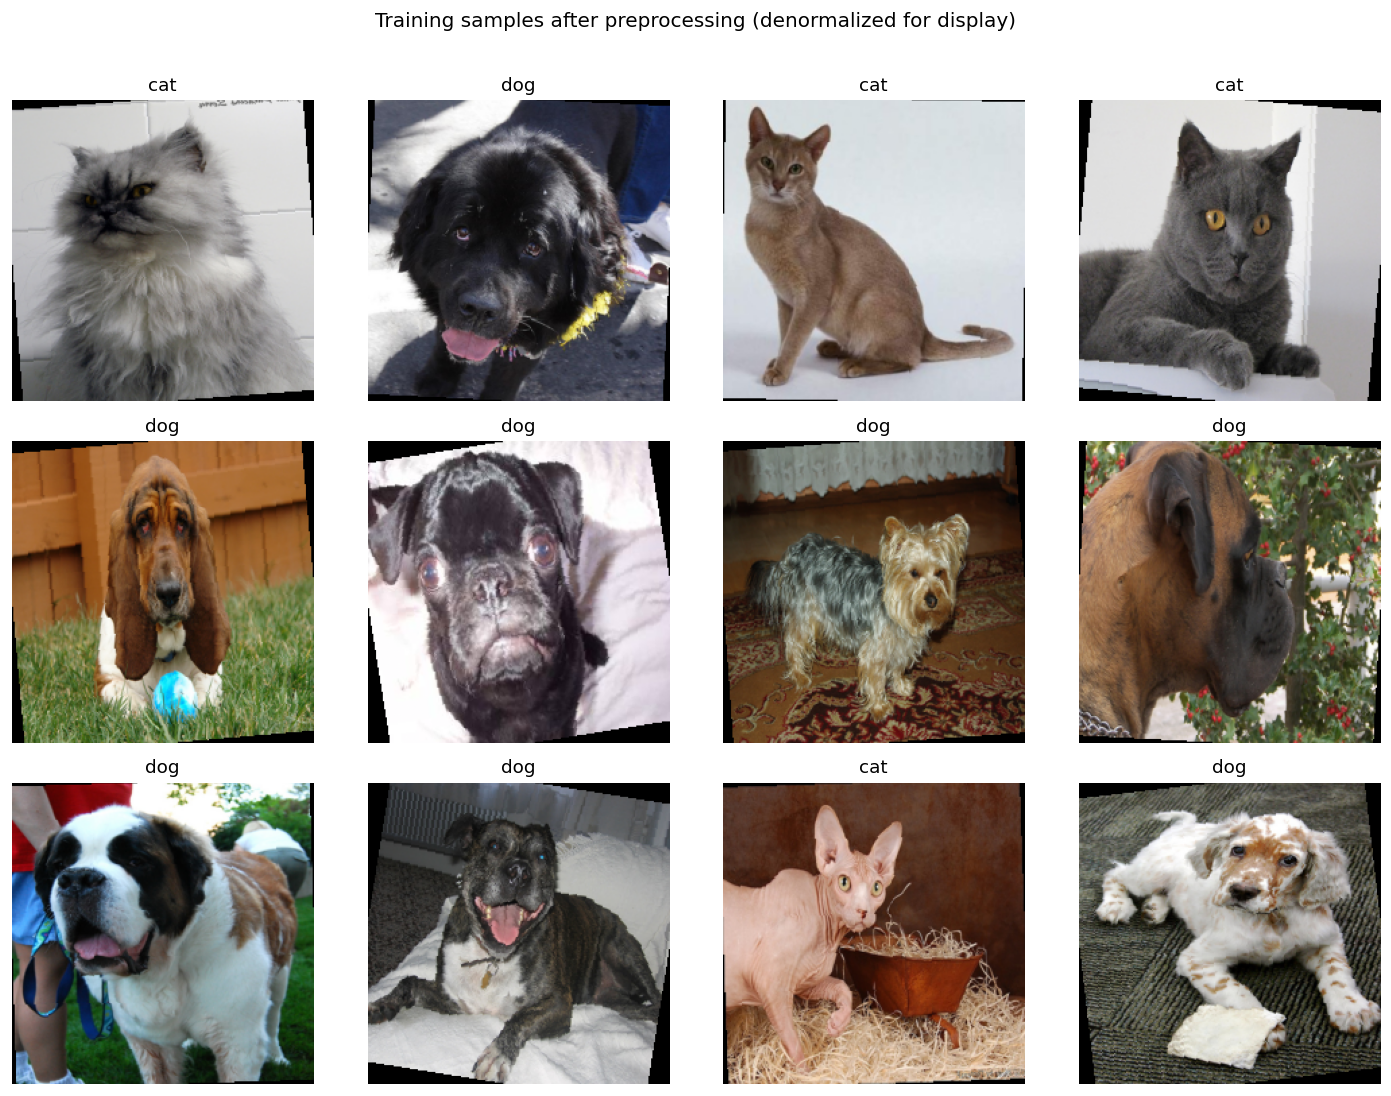

In [9]:
def denormalize(batch):
    mean = torch.tensor(IMAGENET_MEAN).view(1, 3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(1, 3, 1, 1)
    return (batch.detach().cpu() * std + mean).clamp(0, 1)

images, labels = next(iter(train_loader))
preview_images = denormalize(images[:12])
class_names = ["cat", "dog"]

figure, axes = plt.subplots(3, 4, figsize=(12, 9))
for index, axis in enumerate(axes.flat):
    axis.imshow(preview_images[index].permute(1, 2, 0).numpy())
    axis.set_title(class_names[int(labels[index])])
    axis.axis("off")
figure.suptitle("Training samples after preprocessing (denormalized for display)", y=1.01)
figure.tight_layout()
figure.savefig(Path("figures") / "dataset_samples.png", dpi=300, bbox_inches="tight")
plt.show()

## Preprocessing and perturbation preview

The perturbation families used in the stability study are shown below on a single image. They operate on the **normalized** tensor, exactly as they will during evaluation. One representative parameter value is displayed per family.

| Family | Values used downstream | Intended semantic effect |
|---|---|---|
| Rotation | −15° … 15° | Camera roll and framing jitter |
| Brightness | 0.8×, 1.2× | Exposure change |
| Gaussian noise | σ = 0.01, 0.03, 0.05 | Sensor noise |
| Resize | 128, 180, 256 px | Resolution loss |

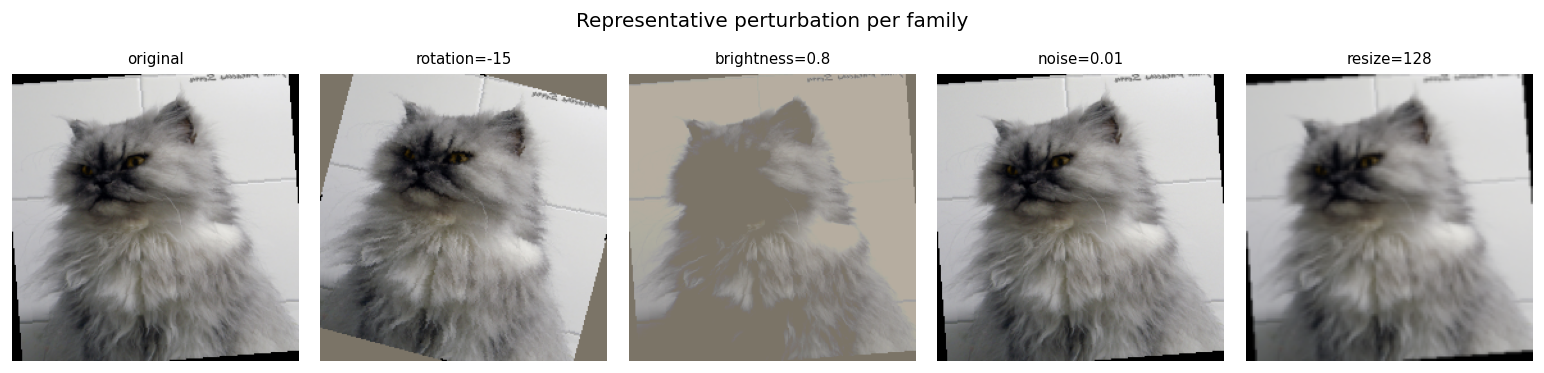

In [10]:
from src.perturbations.transforms import make_perturbations

single_image = images[:1]
preview_items = [("original", single_image)]
selected = {}
for perturbation in make_perturbations():
    selected.setdefault(perturbation.name, perturbation)
for perturbation in selected.values():
    preview_items.append((f"{perturbation.name}={perturbation.parameter:g}", perturbation.apply(single_image)))

figure, axes = plt.subplots(1, len(preview_items), figsize=(2.6 * len(preview_items), 3.0))
for axis, (title, batch) in zip(axes, preview_items):
    axis.imshow(denormalize(batch)[0].permute(1, 2, 0).numpy())
    axis.set_title(title, fontsize=9)
    axis.axis("off")
figure.suptitle("Representative perturbation per family", y=1.02)
figure.tight_layout()
figure.savefig(Path("figures") / "perturbation_preview.png", dpi=300, bbox_inches="tight")
plt.show()

## Data-quality checks

These checks are cheap and catch the most common protocol failures before training: label leakage between training and validation, out-of-range labels, and accidental use of the wrong target type.

In [11]:
train_indices = set(train_dataset.indices)
validation_indices = set(validation_dataset.indices)

checks = pd.Series({
    "train_validation_disjoint": len(train_indices & validation_indices) == 0,
    "train_labels_in_range": bool(np.isin(binary_labels(train_dataset), [0, 1]).all()),
    "validation_labels_in_range": bool(np.isin(binary_labels(validation_dataset), [0, 1]).all()),
    "test_labels_in_range": bool(np.isin(binary_labels(test_dataset), [0, 1]).all()),
    "validation_fraction_matches_config": abs(
        len(validation_dataset) / (len(train_dataset) + len(validation_dataset)) - 0.15
    ) < 0.01,
}, name="passed").to_frame()
checks

,passed
train_validation_disjoint,True
train_labels_in_range,True
validation_labels_in_range,True
test_labels_in_range,True
validation_fraction_matches_config,True


## Interpretation guide and next steps

Use the tables above to answer three questions before modelling:

1. **Is the task balanced enough for plain cross-entropy?** Report the cat/dog ratio per split. A ratio close to 1 supports accuracy as a headline metric; otherwise report per-class recall and macro-F1.
2. **Does the validation partition preserve the training distribution?** Compare class shares and geometry across splits. Large shifts would invalidate validation-based checkpoint selection.
3. **Are the perturbations semantically mild?** The preview should show identity-preserving changes. If a perturbation visibly changes the object category, it should be excluded from the stability analysis rather than treated as noise.

Proceed to `02_model_training.ipynb`.